# 1 · A realistic social network from the feature-driven graph model

**Goal.** Tune Băbeanu's feature-driven random graph so that it has (i) a heavy-tailed degree distribution, (ii) high clustering, (iii) short paths, (iv) communities.

**Model.** Node $i$ has a feature vector $x_i$ and a sociability parameter $\lambda_i>0$. With $s_{ij}$ the fraction of shared features,

$$p_{ij}=s_{ij}^{\lambda_i\lambda_j}=\exp(-\lambda_i\lambda_j\,d_{ij}),\qquad d_{ij}=-\log s_{ij}.$$

So $d_{ij}$ is a distance in feature space and $1/\lambda_i$ acts like a hidden "fitness": small $\lambda$ → hub, large $\lambda$ → connects only to near-identical nodes.

**Approach in one paragraph.** Edges are independent, so every *expected* network statistic is a smooth, closed-form function of the parameters. We therefore never sample graphs inside the optimiser. We give each node its own $\theta_i=\log\lambda_i$ and minimise a deterministic cost with exact gradients. The $\lambda$'s control the degree sequence; the *geometry of the features* controls clustering and communities, and is chosen in a small outer search.

In [1]:
import os
import time
import numpy as np
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wasserstein_distance

rng = np.random.default_rng(7)          # one random stream for the whole notebook
os.makedirs('data', exist_ok=True)
os.makedirs('figures', exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## 1.1 Features, similarity, target degrees

`make_features` generalises the earlier `random_LFVC`: there are `C` communities, each with a random prototype vector over `q` possible values per feature; every node copies `D` of its `F` features from its community prototype and draws the rest at random. `D/F` sets how strong communities are; `F` and `q` set how fine-grained the feature space is.

The target degree distribution is a truncated power law $P(k)\propto k^{-\gamma}$ on $[k_{min},k_{max}]$, represented by its $n$ quantiles.

In [2]:
def make_features(n, F, q, C, D, rng):
    """n people, F features with q values each, C communities.
    Each person copies D of their F features from their community's prototype; the rest are random."""
    proto = rng.integers(0, q, size=(C, F))         # one prototype vector per community
    comm = rng.integers(0, C, size=n)               # community of each person
    x = rng.integers(0, q, size=(n, F))             # start fully random
    for i in range(n):
        copied = rng.choice(F, D, replace=False)
        x[i, copied] = proto[comm[i], copied]
    return x, comm


def distance_matrix(x):
    """d_ij = -log(share of features i and j have in common). Pairs sharing nothing get a huge distance (p = 0)."""
    S = (x[:, None, :] == x[None, :, :]).mean(-1)
    np.fill_diagonal(S, 0.0)                        # no self-ties
    with np.errstate(divide='ignore'):
        Dm = -np.log(S)
    Dm[S == 0] = 1e6
    return Dm


def target_quantiles(n, gamma, kmin, kmax):
    """The n quantiles of a power law P(k) ~ k^-gamma on [kmin, kmax], in ascending order."""
    u = (np.arange(n) + 0.5) / n
    a, b = kmin**(1 - gamma), kmax**(1 - gamma)
    return (a + (b - a) * u)**(1 / (1 - gamma))


def edge_probs(theta, Dm):
    """Tie probabilities p_ij = exp(-lambda_i * lambda_j * d_ij), with lambda = exp(theta)."""
    lam = np.exp(theta)
    return np.exp(-np.outer(lam, lam) * Dm)

## 1.2 The cost function

**Degree term (the one that matters).** Let $\bar k_i=\sum_j p_{ij}$ be the expected degree, $\bar k_{(r)}$ its sorted values and $k^*_{(r)}$ the target quantiles:

$$J_{deg}(\theta)=\frac1n\sum_{r=1}^{n}\big(\log \bar k_{(r)}-\log k^*_{(r)}\big)^2 .$$

This is the squared 1-D Wasserstein-2 distance between the two distributions of *log-degree*. Why this form:

* **Deterministic** – it uses expected degrees, not a sampled graph, so there is no sampling noise to average away.
* **Permutation-invariant** – it constrains the *distribution*; the optimiser decides which node becomes a hub.
* **Log scale** – a hub at 80 instead of 100 costs the same as a leaf at 4 instead of 5, so the tail is fitted as carefully as the bulk.

**Exact gradient.** Since $\partial p_{ij}/\partial\theta_i = p_{ij}\log p_{ij}$, for any cost with $G_{ij}=\partial J/\partial p_{ij}$ (symmetric),

$$\frac{\partial J}{\partial\theta_m}=2\sum_j G_{mj}\,p_{mj}\log p_{mj},$$

one $O(n^2)$ matrix operation. We use Adam on the full gradient (for much larger $n$ one would subsample rows, which makes it SGD proper).

**Optional terms**, kept for the experiment in §1.5: an isolation penalty $\frac1n\sum_i e^{-\bar k_i}$ (expected fraction of isolated nodes) and expected transitivity $\bar C = \mathrm{tr}(P^3)/\sum_i(\bar k_i^2-\sum_j p_{ij}^2)$.

In [3]:
def cost_and_grad(theta, Dm, k_target, w_iso=0.0, w_clu=0.0):
    """Cost J and its exact gradient with respect to theta = log(lambda).
    J_deg compares sorted expected log-degrees with the target quantiles.
    Optional extra terms: isolation penalty (w_iso) and expected transitivity (w_clu, maximised)."""
    P = edge_probs(theta, Dm)
    k = P.sum(1)                                    # expected degree of each person
    n = len(k)

    # degree term
    order = np.argsort(k)
    resid = np.log(k[order] + 1e-12) - np.log(k_target)
    J_deg = np.mean(resid**2)
    dJ_dk = np.zeros(n)
    dJ_dk[order] = 2 * resid / n / (k[order] + 1e-12)
    G = (dJ_dk[:, None] + dJ_dk[None, :]) / 2       # dJ/dP, symmetrised
    J = J_deg
    info = {'J_deg': J_deg}

    # optional: penalise isolated people (expected share with degree 0)
    if w_iso:
        e = np.exp(-k)
        J += w_iso * e.mean()
        G += w_iso * (-(e[:, None] + e[None, :]) / (2 * n))

    # optional: reward expected transitivity C = tr(P^3) / (number of wedges)
    if w_clu:
        P2 = P @ P
        triangles = np.einsum('ij,ij->', P2, P)
        wedges = (k**2 - (P**2).sum(1)).sum()
        C_exp = triangles / wedges
        dC = 3 * P2 / wedges - C_exp / wedges * ((k[:, None] + k[None, :]) - 2 * P)
        J += -w_clu * C_exp
        G += -w_clu * dC
        info['C_exp'] = C_exp

    # chain rule: dp_ij/dtheta_i = p_ij * log(p_ij)
    grad = 2 * (G * P * np.log(np.clip(P, 1e-300, 1))).sum(1)
    return J, grad, info


def fit(Dm, k_target, iters=600, lr=0.05, theta0=None, **kw):
    """Minimise the cost with Adam. Returns fitted theta and the history of J_deg."""
    n = Dm.shape[0]
    theta = np.zeros(n) if theta0 is None else theta0.copy()
    m = np.zeros(n)
    v = np.zeros(n)
    hist = []
    for t in range(1, iters + 1):
        J, g, info = cost_and_grad(theta, Dm, k_target, **kw)
        hist.append(info['J_deg'])
        m = 0.9 * m + 0.1 * g                       # Adam moment estimates
        v = 0.999 * v + 0.001 * g * g
        theta -= lr * (m / (1 - 0.9**t)) / (np.sqrt(v / (1 - 0.999**t)) + 1e-8)
    return theta, np.array(hist)


def sample_graph(P, rng):
    """Build one network: each tie is an independent coin flip with probability p_ij."""
    A = np.triu(rng.random(P.shape) < P, 1)
    return nx.from_numpy_array(A | A.T)


def graph_stats(G, comm=None):
    """Summary statistics of a network (plus modularity of the planted communities if given)."""
    n = G.number_of_nodes()
    deg = np.array([d for _, d in G.degree()])
    giant = G.subgraph(max(nx.connected_components(G), key=len))
    louvain = nx.community.louvain_communities(G, seed=0)
    out = {'<k>': deg.mean(),
           'k_max': deg.max(),
           'C_avg': nx.average_clustering(G),
           'C_glob': nx.transitivity(G),
           'path_len': nx.average_shortest_path_length(giant),
           'giant': giant.number_of_nodes() / n,
           'Q_louvain': nx.community.modularity(G, louvain),
           'assort': nx.degree_assortativity_coefficient(G)}
    if comm is not None:
        out['Q_planted'] = nx.community.modularity(G, [set(np.where(comm == c)[0]) for c in np.unique(comm)])
    return out

## 1.3 Why the earlier approach struggled

The earlier code drew all $\lambda_i$ from a 3-parameter distribution $(w,a,b)$ and tuned those 3 numbers with SPSA on a Wasserstein distance between the *sampled* degree tail ($k\ge5$) and a *sampled* power law. Below, that loss is evaluated 15× at the SPSA starting guess and at the parameter sets recorded in the old script (features regenerated here with the old settings: $n=500$, 10 binary features, 2 categories).

In [4]:
def sample_lambda_old(n, w, a, b, rng):
    """Old approach: draw every lambda from one piecewise-exponential distribution (w, a, b), by inverse CDF."""
    aw = min(a * w, 50.0)
    A = 1.0 / ((np.exp(aw) - 1) / a + np.exp(aw) / b)
    B = A * np.exp(aw)
    Fw = A * (np.exp(aw) - 1) / a
    u = rng.random(n)
    out = np.zeros(n)
    low = u <= Fw
    out[low] = np.log(1 + a * u[low] / A) / a
    out[~low] = w - np.log(np.clip(1 - b * (u[~low] - Fw) / B, 1e-10, 1)) / b
    return out


def old_loss(Dm, params, rng, gamma=2.5, k_cut=5, n_graphs=3):
    """Old loss: Wasserstein distance between the sampled degree tail (k >= k_cut) and a sampled power law."""
    degs = []
    for _ in range(n_graphs):
        lam = sample_lambda_old(Dm.shape[0], *params, rng)
        G = sample_graph(np.exp(-np.outer(lam, lam) * Dm), rng)
        degs += [d for _, d in G.degree()]
    degs = np.array(degs)
    tail = degs[degs >= k_cut]
    if len(tail) < 0.3 * len(degs):                 # the old code returned 1e6 here
        return np.nan, degs.mean()
    target = k_cut * (1 - rng.random(len(tail)))**(-1 / (gamma - 1))
    return wasserstein_distance(tail, target), degs.mean()


# old settings: n = 500, 10 binary features, 2 communities
x_old, comm_old = make_features(500, 10, 2, 2, 5, rng)
Dm_old = distance_matrix(x_old)
old_sets = {'SPSA start (3.0, 2.475, 1.3645)': (3.0, 2.475, 1.3645),
            'start, shifted by one SPSA step (×e^0.2)': tuple(np.array((3.0, 2.475, 1.3645)) * np.exp(0.2)),
            'recorded result (5.0, 2.475, 1.3645)': (5.0, 2.475, 1.3645),
            'recorded result (5.02, 4.03, 0.81)': (5.015, 4.033, 0.807),
            'used for generation (11.34, 0.655, 0.361)': (11.339, 0.655, 0.361)}

# score each old parameter set 15 times
rows = []
for name, p in old_sets.items():
    r = np.array([old_loss(Dm_old, np.array(p), rng) for _ in range(15)])
    ok = ~np.isnan(r[:, 0])
    rows.append({'parameters': name,
                 'loss (mean)': r[ok, 0].mean() if ok.any() else np.nan,
                 'loss (sd)': r[ok, 0].std() if ok.any() else np.nan,
                 'hits 1e6 guard': 1 - ok.mean(),
                 '<k>': r[:, 1].mean()})

# the network the old approach actually generated, kept for comparison
lam = sample_lambda_old(500, 11.339, 0.655, 0.361, rng)
G_old = sample_graph(np.exp(-np.outer(lam, lam) * Dm_old), rng)
stats_old = graph_stats(G_old, comm_old)
pd.DataFrame(rows).set_index('parameters').round(2)

,loss (mean),loss (sd),hits 1e6 guard,<k>
parameters,,,,
"SPSA start (3.0, 2.475, 1.3645)",8.52,1.42,0.0,17.60
"start, shifted by one SPSA step (×e^0.2)",4.65,1.33,0.0,7.77
"recorded result (5.0, 2.475, 1.3645)",NaN,NaN,1.0,2.95
"recorded result (5.02, 4.03, 0.81)",NaN,NaN,1.0,2.42
"used for generation (11.34, 0.655, 0.361)",NaN,NaN,1.0,1.96


What this shows:

1. **The loss has a cliff.** Its safeguard returns $10^6$ whenever fewer than 30 % of nodes have degree ≥ 5. Every parameter set the old runs ended on sits on that plateau, where the finite-difference gradient is zero or enormous. The resulting graphs have mean degree ≈ 2–3 and no giant component – the "too many antisocial nodes" problem.
2. **Nothing pins the density.** A tail-only distance to a power law starting at $k_{cut}$ does not say what the mean degree should be, so a small parameter change moves it from 18 to 8.
3. **It is noisy and expensive.** Where the loss is defined its sd is ~15–30 % of its value, and each SPSA step needs 6 sampled graphs.
4. **Three parameters cannot shape $n$ degrees.** A node's degree depends on $\lambda_i$ *and* on where $x_i$ sits in feature space; an i.i.d. distribution for $\lambda$ ignores the second part.

## 1.4 Fit: degree sequence

$n=1024$ (so that it can later be compared with a $32\times32$ lattice), target $\gamma=2.5$, $k\in[6,150]$, mean degree ≈ 14.

**Why these numbers.** A tie here is someone you talk to often enough to pick up everyday cultural traits from. The closest layer in the personal-network literature is Dunbar's *sympathy group* of about 15 people (Zhou, Sornette, Hill & Dunbar 2005), between the core discussion network of 2–3 confidants (McPherson, Smith-Lovin & Brashears 2006) and the wider layers of 50 and 150. The cap of 150 is Dunbar's number: nobody maintains more than about 150 meaningful ties. Notebook 2 shows that the sorting results depend strongly on this choice (mean degree 7 vs 10 vs 14), so it is tested, not just assumed.

In [5]:
n, GAMMA, KMIN, KMAX = 1024, 2.5, 6, 150       # people, power-law exponent, degree range
k_target = target_quantiles(n, GAMMA, KMIN, KMAX)

x0, comm0 = make_features(n, 10, 4, 8, 8, rng)  # a first feature geometry, used in 1.5
Dm0 = distance_matrix(x0)

t0 = time.time()
theta0, hist0 = fit(Dm0, k_target)
print(f'fit: {time.time() - t0:.1f}s, final J_deg = {hist0[-1]:.2e}, target mean degree = {k_target.mean():.2f}')

fit: 9.0s, final J_deg = 1.91e-19, target mean degree = 14.52


## 1.5 Can the same optimiser also raise clustering? (No – and why)

Add the expected-transitivity term with weight $w_{clu}$ and re-optimise $\lambda$ on the same features.

In [6]:
rows = []
for w in [0, 0.3, 1, 3]:                        # weight on the clustering term
    th = theta0 if w == 0 else fit(Dm0, k_target, iters=500, lr=0.02, theta0=theta0, w_clu=w)[0]
    J, _, info = cost_and_grad(th, Dm0, k_target, w_clu=1e-12)
    s = graph_stats(sample_graph(edge_probs(th, Dm0), rng), comm0)
    rows.append({'w_clu': w, 'J_deg': info['J_deg'], **s})
pd.DataFrame(rows).set_index('w_clu').round(3)

,J_deg,<k>,k_max,C_avg,C_glob,path_len,giant,Q_louvain,assort,Q_planted
w_clu,,,,,,,,,,
0.0,0.000,14.525,149,0.277,0.202,3.721,1.000,0.728,-0.029,0.734
0.3,0.010,15.160,99,0.241,0.355,3.498,0.990,0.700,0.466,0.670
1.0,0.082,17.912,116,0.292,0.466,3.114,0.998,0.517,0.514,0.487
3.0,0.274,21.244,138,0.401,0.576,2.832,0.987,0.319,0.439,0.291


**Reading the table.** Global transitivity goes up, but only because the optimiser builds a *rich club*: high-degree nodes wire densely to each other (degree assortativity jumps from ≈0 to ≈0.7, far above real social networks), the degree fit degrades (`J_deg` rises, mean degree drifts) and the planted communities dissolve (`Q` falls). Average *local* clustering – the small-world property we actually care about – barely moves (it first dips, then gains a few points only once the degree fit and the giant component are already degrading). That is gaming the metric, not a more realistic network.

The structural reason: matching $n$ expected degrees uses up all $n$ free parameters $\lambda_i$. Whatever clustering is left is decided by the distances $d_{ij}$, i.e. by the features. So the roles separate cleanly:

| knob | controls | how it is set |
|---|---|---|
| $\lambda_i$ (one per node) | degree distribution, connectivity | gradient descent on $J_{deg}$ |
| feature geometry $(F, q, C, D)$ | clustering, communities, path length | small outer search |

## 1.6 Outer search over feature geometry

For each candidate geometry: generate features, fit $\lambda$ (inner loop), sample 2 graphs, and score them against social-network targets

$$J_{struct}=\Big(\tfrac{C_{avg}-0.35}{0.10}\Big)^2+\Big(\tfrac{Q-0.60}{0.15}\Big)^2+\Big(\tfrac{1-\text{giant}}{0.02}\Big)^2 .$$

Here $Q$ is the modularity of the *planted* communities: the offline groups (workplace, church, school) whose shared traits create the ties. Scoring on these, rather than on whatever groups Louvain finds, makes sure the communities that drive homophily are also the ones visible in the network. The targets are choices, not facts: $C_{avg}\approx0.35$ and modularity $\approx0.6$ are typical of friendship / online social graphs. Path length is not targeted – it comes out short automatically once the degree distribution is heavy-tailed – but it is reported.

In [7]:
def J_struct(s):
    """Distance from social-network targets: clustering 0.35, planted modularity 0.6, everyone connected."""
    return (((s['C_avg'] - 0.35) / 0.10)**2
            + ((s['Q_planted'] - 0.60) / 0.15)**2
            + ((1 - s['giant']) / 0.02)**2)


# candidate geometries: F features, q values, 8 communities, D = half or three quarters of F copied
grid = [(F, q, 8, int(round(F * d))) for F in (6, 8, 10, 14) for q in (3, 4) for d in (0.5, 0.75)]

res = []
t0 = time.time()
for (F, q, Cc, D) in grid:
    r = np.random.default_rng(100 + F * 10 + q + D)
    x, comm = make_features(n, F, q, Cc, D, r)
    Dm = distance_matrix(x)
    th, h = fit(Dm, k_target, iters=400)                 # inner loop: fit the lambdas
    P = edge_probs(th, Dm)
    ss = pd.DataFrame([graph_stats(sample_graph(P, r), comm) for _ in range(2)]).mean().to_dict()
    res.append({'F': F, 'q': q, 'C': Cc, 'D': D, 'J_deg': h[-1], **ss, 'J_struct': J_struct(ss)})

search = pd.DataFrame(res).sort_values('J_struct').reset_index(drop=True)
print(f'{time.time() - t0:.0f}s')
search.round(3)

201s


,F,q,C,D,J_deg,<k>,k_max,C_avg,C_glob,path_len,giant,Q_louvain,assort,Q_planted,J_struct
0,8,3,8,6,0.0,14.476,151.0,0.287,0.207,3.240,1.000,0.706,-0.047,0.695,0.798
1,10,3,8,8,0.0,14.583,147.0,0.302,0.249,3.878,1.000,0.745,0.016,0.734,1.027
2,8,4,8,6,0.0,14.558,143.5,0.263,0.181,3.306,1.000,0.718,-0.092,0.684,1.067
3,10,4,8,8,0.0,14.496,154.0,0.306,0.192,3.348,1.000,0.772,-0.106,0.772,1.513
4,6,3,8,4,0.0,14.654,143.5,0.347,0.289,3.319,1.000,0.588,0.165,0.378,2.201
5,14,3,8,10,0.0,14.382,150.0,0.196,0.119,2.986,1.000,0.620,-0.107,0.617,2.389
6,6,4,8,4,0.0,14.657,149.5,0.194,0.154,3.113,1.000,0.541,0.018,0.492,2.950
7,14,4,8,10,0.0,14.452,144.0,0.167,0.121,3.177,1.000,0.614,-0.025,0.602,3.350
8,6,3,8,3,0.0,14.723,136.5,0.187,0.158,3.062,1.000,0.450,0.071,0.235,8.574
9,10,4,8,5,0.0,14.676,148.5,0.088,0.074,2.816,1.000,0.338,-0.042,0.291,11.087


## 1.7 Final network and comparison with null models

In [8]:
# rebuild the best geometry and fit it longer
best = search.iloc[0]
F, q, Cc, D = int(best.F), int(best.q), int(best.C), int(best.D)
print('chosen geometry: F=%d, q=%d, C=%d, D=%d' % (F, q, Cc, D))
r = np.random.default_rng(100 + F * 10 + q + D)
x, comm = make_features(n, F, q, Cc, D, r)
Dm = distance_matrix(x)
theta, hist = fit(Dm, k_target, iters=800)
P = edge_probs(theta, Dm)

# 10 sampled networks; the first one is "the" network used from here on
samples = [sample_graph(P, r) for _ in range(10)]
G = samples[0]
deg = [d for _, d in G.degree()]

# null models with the same density / the same degrees
ER = nx.gnm_random_graph(n, G.number_of_edges(), seed=1)
CM = nx.Graph(nx.configuration_model(deg, seed=1))
CM.remove_edges_from(nx.selfloop_edges(CM))

fd = pd.DataFrame([graph_stats(g, comm) for g in samples])
table = pd.DataFrame({'feature-driven (mean of 10)': fd.mean(),
                      '  (sd)': fd.std(),
                      'config. model (same degrees)': graph_stats(CM),
                      'Erdős–Rényi (same density)': graph_stats(ER),
                      'old approach (n=500)': stats_old}).T.round(3)
table

chosen geometry: F=8, q=3, C=8, D=6


,<k>,C_avg,C_glob,Q_louvain,Q_planted,assort,giant,k_max,path_len
feature-driven (mean of 10),14.545,0.288,0.207,0.705,0.693,-0.044,1.000,147.300,3.246
(sd),0.129,0.004,0.003,0.004,0.005,0.005,0.000,6.783,0.024
config. model (same degrees),14.160,0.053,0.048,0.229,NaN,-0.031,1.000,129.000,2.769
Erdős–Rényi (same density),14.566,0.015,0.014,0.228,NaN,-0.014,1.000,26.000,2.854
old approach (n=500),1.908,0.452,1.000,0.966,0.400,1.000,0.024,11.000,1.000


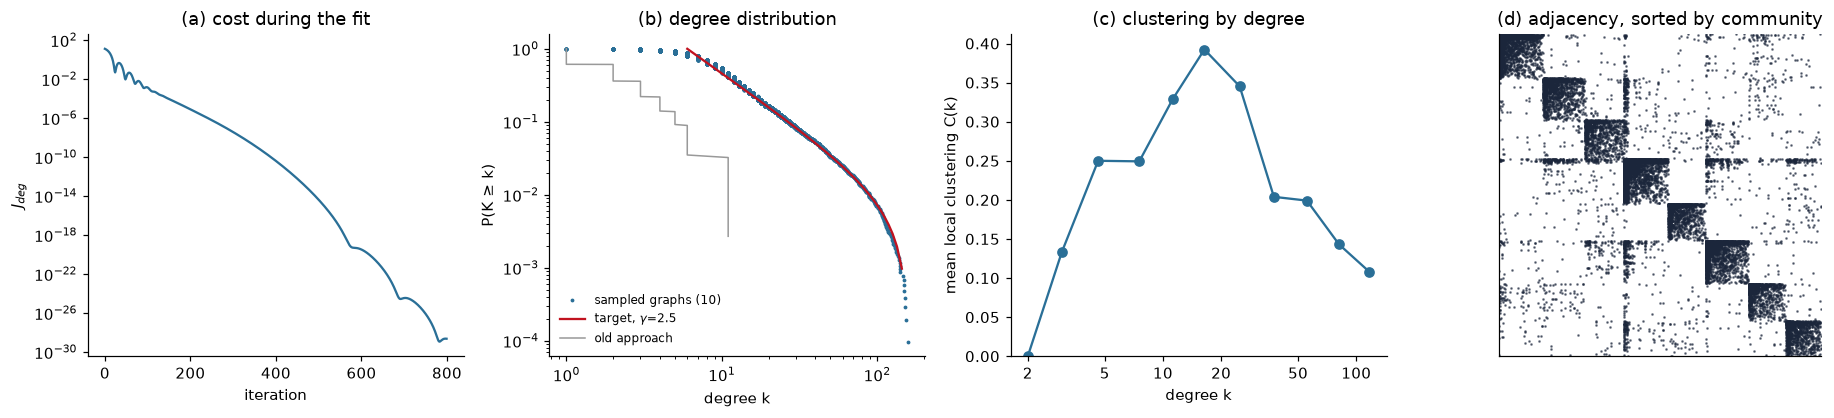

In [9]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.9))

# (a) cost during the fit
ax[0].semilogy(hist, color='#2a6f97')
ax[0].set(xlabel='iteration', ylabel='$J_{deg}$', title='(a) cost during the fit')

# (b) degree distribution: sampled vs target vs old approach
ks = np.sort(np.concatenate([[d for _, d in g.degree()] for g in samples]))
ax[1].loglog(ks, 1 - np.arange(len(ks)) / len(ks), '.', ms=3, color='#2a6f97', label='sampled graphs (10)')
ax[1].loglog(k_target, 1 - np.arange(n) / n, '-', color='#c1121f', lw=1.5, label=f'target, $\\gamma$={GAMMA}')
ko = np.sort([d for _, d in G_old.degree() if d > 0])
ax[1].loglog(ko, 1 - np.arange(len(ko)) / len(ko), '-', color='0.6', lw=1, label='old approach')
ax[1].set(xlabel='degree k', ylabel='P(K ≥ k)', title='(b) degree distribution')
ax[1].legend(frameon=False, fontsize=8)

# (c) mean local clustering by degree (log bins)
dg = np.array(deg)
cl = np.array(list(nx.clustering(G).values()))
bins = np.unique(np.round(np.logspace(np.log10(2), np.log10(dg.max()), 12)))
in_bin = [(dg >= a) & (dg < b) for a, b in zip(bins[:-1], bins[1:])]
mid = [dg[m].mean() for m in in_bin if m.any()]
ck = [cl[m].mean() for m in in_bin if m.any()]
ax[2].semilogx(mid, ck, 'o-', color='#2a6f97')
ax[2].set(xlabel='degree k', ylabel='mean local clustering C(k)', title='(c) clustering by degree', ylim=(0, None))
ax[2].set_xticks([2, 5, 10, 20, 50, 100])
ax[2].set_xticklabels(['2', '5', '10', '20', '50', '100'])
ax[2].minorticks_off()

# (d) adjacency matrix, people sorted by community then degree
o = np.lexsort((-dg, comm))
A = nx.to_numpy_array(G)[np.ix_(o, o)]
ax[3].spy(A, markersize=0.25, color='#1b263b')
ax[3].set(title='(d) adjacency, sorted by community', xticks=[], yticks=[])

plt.tight_layout()
plt.savefig('figures/01_network_fit.png', dpi=160, bbox_inches='tight')
plt.show()

**How to read the four panels.** (a) The cost falls to essentially zero: the expected friend counts match the target. (b) Share of people with at least k friends, on log–log axes; a straight-ish falling line is the signature of a heavy tail (most people have few ties, a handful have very many). Blue dots = 10 sampled networks, red = target, grey = old approach. (c) Average clustering of people with k friends: mid-degree people sit in the tightest friend groups, hubs bridge groups and so have low clustering. (d) Each dot is a tie; people are ordered by community, so dense squares on the diagonal = communities, scattered dots = ties between communities.

## 1.7b Drawing the network

Same drawing style as the earlier code: spring layout, node size and colour by degree, and a community layout (each community laid out on its own, communities placed around each other). Left: the network produced by the old tuning. Middle and right: the new network.

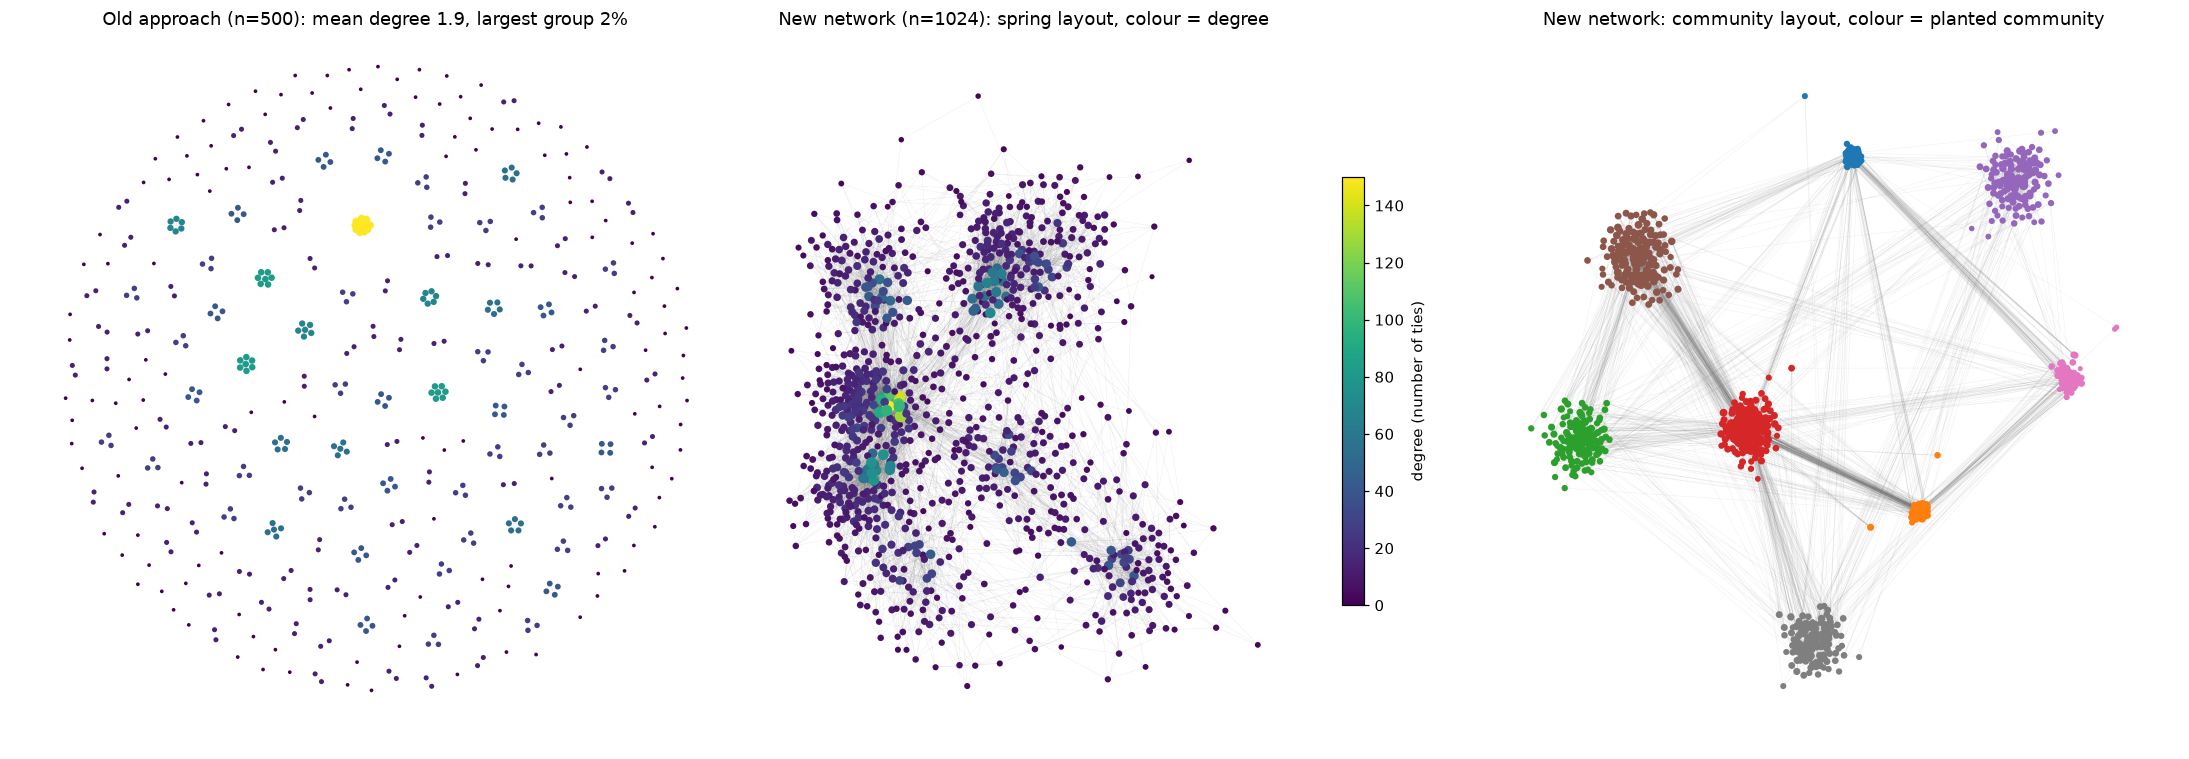

In [10]:
def community_layout(g, parts, seed=42, outer_scale=4.0, inner_scale=1.0):
    """Lay out communities as super-nodes first, then lay out each community around its centre."""
    sup = nx.Graph()
    sup.add_nodes_from(range(len(parts)))
    label = {v: c for c, p in enumerate(parts) for v in p}
    for u, v in g.edges():
        if label[u] != label[v]:
            w = sup.get_edge_data(label[u], label[v], {'weight': 0})['weight']
            sup.add_edge(label[u], label[v], weight=w + 1)
    centres = nx.spring_layout(sup, scale=outer_scale, k=3, seed=seed, weight='weight')
    pos = {}
    for c, p in enumerate(parts):
        size = inner_scale * np.sqrt(len(p) / len(g)) * 2.2
        pos.update(nx.spring_layout(g.subgraph(p), center=centres[c], scale=size, seed=seed))
    return pos


def draw_by_degree(g, pos, ax, title, vmax=None):
    """Draw a network with node size and colour by degree."""
    dd = np.array([g.degree(v) for v in g.nodes()])
    nx.draw_networkx_edges(g, pos, ax=ax, width=0.3, alpha=0.12, edge_color='0.4')
    sc = nx.draw_networkx_nodes(g, pos, ax=ax, node_size=6 + 5 * np.sqrt(dd), node_color=dd, cmap='viridis',
                                vmin=0, vmax=vmax or dd.max(), linewidths=0)
    ax.set_title(title, fontsize=12)
    ax.axis('off')
    return sc


fig, ax = plt.subplots(1, 3, figsize=(20, 7))

# left: the old approach's network
pos_old = nx.spring_layout(G_old, seed=42, k=1.5 / np.sqrt(G_old.number_of_nodes()))
draw_by_degree(G_old, pos_old, ax[0],
               f'Old approach (n=500): mean degree {stats_old["<k>"]:.1f}, largest group {stats_old["giant"]:.0%}')

# middle: the new network, spring layout
pos_spring = nx.spring_layout(G, seed=42, k=1.5 / np.sqrt(n), iterations=100)
sc1 = draw_by_degree(G, pos_spring, ax[1], f'New network (n={n}): spring layout, colour = degree')
plt.colorbar(sc1, ax=ax[1], shrink=0.6, label='degree (number of ties)')

# right: the new network, community layout, colour = planted community
parts = [set(np.where(comm == c)[0]) for c in np.unique(comm)]
pos_comm = community_layout(G, parts)
cols = plt.cm.tab10(np.arange(10))
dd = np.array([G.degree(v) for v in G.nodes()])
nx.draw_networkx_edges(G, pos_comm, ax=ax[2], width=0.3, alpha=0.1, edge_color='0.4')
nx.draw_networkx_nodes(G, pos_comm, ax=ax[2], node_size=6 + 5 * np.sqrt(dd),
                       node_color=[cols[comm[v] % 10] for v in G.nodes()], linewidths=0)
ax[2].set_title('New network: community layout, colour = planted community', fontsize=12)
ax[2].axis('off')

plt.tight_layout()
plt.savefig('figures/01b_network_drawings.png', dpi=150, bbox_inches='tight')
plt.show()
np.save('data/layout_community.npy', np.array([pos_comm[v] for v in range(n)]))   # reused in notebook 2

**How to read it.** Left: the old tuning leaves most people with zero to two ties; the only dense spots are small cliques of near-identical people (colour scale is per panel). The "network" is dust with a few small clumps. Middle: one connected network with a few large, bright hubs and many small dark nodes. Right: the same network with each planted community in its own colour; communities are dense inside and joined by a thinner web of ties, mostly through hubs.

In [11]:
# save the network for notebook 2
np.savez('data/network.npz', edges=np.array(G.edges()), x=x, comm=comm, lam=np.exp(theta), n=n,
         geometry=np.array([F, q, Cc, D]))
table.to_csv('data/network_stats.csv')
search.to_csv('data/feature_search.csv', index=False)
print('saved data/network.npz :', G.number_of_nodes(), 'nodes,', G.number_of_edges(), 'edges')

# same people and feature table, lower target degrees: used in notebook 2 to test how much mean degree matters
for kmin, tag in ((2.5, 'k7'), (3.6, 'k10')):
    th_k, _ = fit(Dm, target_quantiles(n, GAMMA, kmin, KMAX), iters=800)
    G_k = sample_graph(edge_probs(th_k, Dm), np.random.default_rng(int(10 * kmin)))
    np.savez(f'data/network_{tag}.npz', edges=np.array(G_k.edges()), n=n)
    print(f'saved data/network_{tag}.npz: mean degree {2 * G_k.number_of_edges() / n:.1f}, '
          f'clustering {nx.average_clustering(G_k):.2f}')

saved data/network.npz : 1024 nodes, 7458 edges


saved data/network_k7.npz: mean degree 6.5, clustering 0.41


saved data/network_k10.npz: mean degree 9.2, clustering 0.32


## 1.7c How the expected degree is computed without building a network

**Order of operations.** The feature table comes first. For a given recipe $(F, q, C, D)$ the table $x$ is drawn once and then held fixed. Everything below is *conditional on that table*: the similarity matrix $S$ is computed from it, and only then are the $\lambda$'s fitted.

**The calculation.** Each possible tie is an independent coin flip, $A_{ij}\sim\text{Bernoulli}(p_{ij})$ with $p_{ij}=s_{ij}^{\lambda_i\lambda_j}$. A person's degree is a sum of coin flips, $k_i=\sum_{j\ne i}A_{ij}$, so by linearity of expectation

$$\mathbb E[k_i]=\sum_{j\ne i}p_{ij},\qquad \text{Var}[k_i]=\sum_{j\ne i}p_{ij}(1-p_{ij}).$$

The realised degree follows a Poisson-binomial distribution around that mean. The same independence gives expected triangles, $\mathbb E[\#\triangle]=\tfrac16\,\text{tr}(P^3)$, which is what the clustering term in §1.5 used.

**Naming.** Băbeanu writes the pair exponent as $h_{ij}=\lambda_i\lambda_j$. To avoid a clash with Törnberg's influence homophily $h$, these notebooks call $\lambda_i$ the *sociability parameter* and $\lambda_i\lambda_j$ the *pair exponent*; $h$ always means Törnberg's $h$.

The cell below takes a typical person and the biggest hub and adds up their probabilities by hand.

In [12]:
# tie probabilities p_ij = s_ij^(lambda_i * lambda_j), written out directly
S_ = (x[:, None, :] == x[None, :, :]).mean(-1)
np.fill_diagonal(S_, 0)
lam_fit = np.exp(theta)
P_ = S_ ** np.outer(lam_fit, lam_fit)
np.fill_diagonal(P_, 0)

k_exp = P_.sum(1)                               # expected degree
k_sd = np.sqrt((P_ * (1 - P_)).sum(1))          # its standard deviation
k_real = np.array([G.degree(v) for v in range(n)])

# break E[k] down by how many traits the other person shares, for a typical person and the biggest hub
rows = []
people = (('typical person (median E[k])', int(np.argsort(k_exp)[n // 2])),
          ('biggest hub', int(np.argmax(k_exp))))
for name, v in people:
    for m in range(F, F - 4, -1):
        js = np.where(np.isclose(S_[v] * F, m))[0]
        rows.append({'person': name, 'lambda_i': lam_fit[v], 'shared traits (of %d)' % F: m,
                     'how many others': len(js),
                     'mean p_ij': P_[v, js].mean() if len(js) else 0,
                     'contribution to E[k]': P_[v, js].sum()})
    rows.append({'person': name, 'lambda_i': lam_fit[v], 'shared traits (of %d)' % F: 'all',
                 'how many others': n - 1, 'mean p_ij': P_[v].mean(), 'contribution to E[k]': k_exp[v]})
display(pd.DataFrame(rows).round(4))
print(f'expected vs realised degree over all people: correlation {np.corrcoef(k_exp, k_real)[0, 1]:.3f}, '
      f'mean |E[k] - k| = {np.abs(k_exp - k_real).mean():.2f}, mean predicted sd = {k_sd.mean():.2f}')

,person,lambda_i,shared traits (of 8),how many others,mean p_ij,contribution to E[k]
0,typical person (median E[k]),3.1543,8,0,0.0000,0.0000
1,typical person (median E[k]),3.1543,7,9,0.2566,2.3092
2,typical person (median E[k]),3.1543,6,46,0.1261,5.7994
3,typical person (median E[k]),3.1543,5,114,0.0089,1.0164
4,typical person (median E[k]),3.1543,all,1023,0.0093,9.4800
5,biggest hub,0.9171,8,12,1.0000,12.0000
6,biggest hub,0.9171,7,70,0.6735,47.1436
7,biggest hub,0.9171,6,67,0.4021,26.9409
8,biggest hub,0.9171,5,64,0.2174,13.9111
9,biggest hub,0.9171,all,1023,0.1409,144.2352


expected vs realised degree over all people: correlation 0.983, mean |E[k] - k| = 2.20, mean predicted sd = 2.82


**Reading the table.** The typical person ($\lambda\approx3.2$) has no exact copies. With a pair exponent of around 10, a tie is fairly likely (about 1 in 4) with someone who differs on one trait, about 1 in 8 with two different, and rare beyond that. Their expected degree is essentially "the number of near-copies of me". For the biggest hub ($\lambda\approx0.9$) the exponent is small, so even people who differ on three traits have about a 1 in 5 chance of a tie.

## 1.7d The fitted $\lambda$ distribution

One $\lambda$ per person is still a distribution, just not one drawn from a hand-chosen curve. Its shape is whatever the given feature table needs to produce the target degrees. Up to a point, people with more near-identical others get a *larger* $\lambda$ (pickier), so that they do not end up with too many ties. The people with the very most near-identical others go the other way: the fit makes *them* the hubs, because they reach a hub's degree most easily.

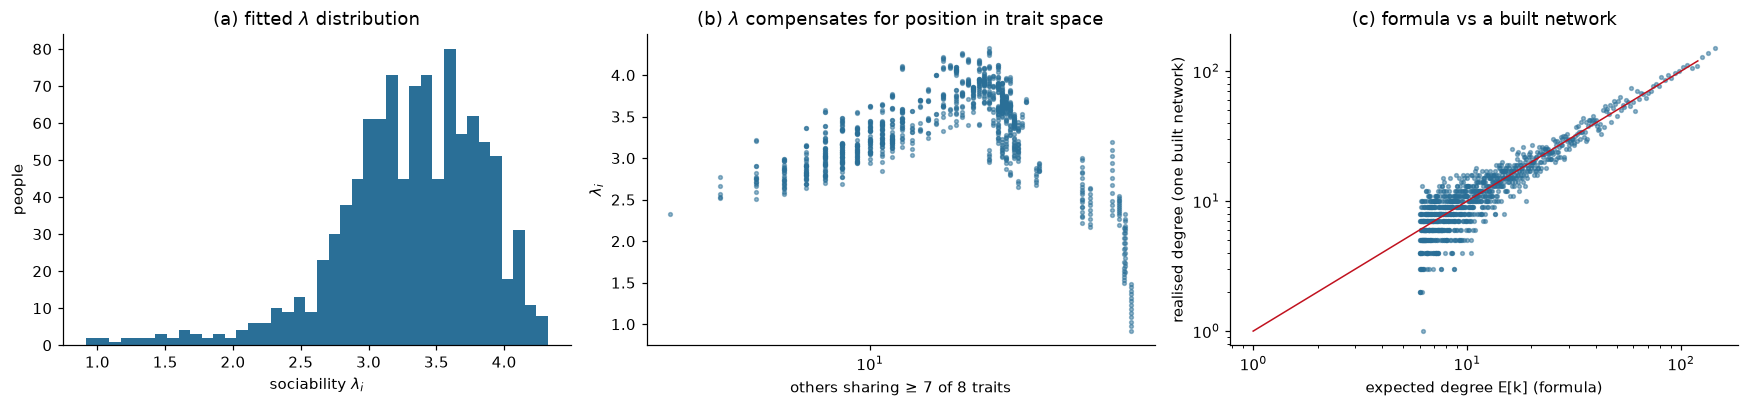

lambda quantiles 5/50/95%: [2.33 3.36 4.06]


In [13]:
near = (S_ >= (F - 1) / F).sum(1)               # others sharing all but at most one trait

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].hist(lam_fit, bins=40, color='#2a6f97')
ax[0].set(xlabel='sociability $\\lambda_i$', ylabel='people', title='(a) fitted $\\lambda$ distribution')

ax[1].scatter(near, lam_fit, s=6, alpha=.5, color='#2a6f97')
ax[1].set(xscale='symlog', xlabel='others sharing ≥ %d of %d traits' % (F - 1, F), ylabel='$\\lambda_i$',
          title='(b) $\\lambda$ compensates for position in trait space')

ax[2].scatter(k_exp, k_real, s=6, alpha=.5, color='#2a6f97')
ax[2].plot([1, 120], [1, 120], color='#c1121f', lw=1)
ax[2].set(xscale='log', yscale='log', xlabel='expected degree E[k] (formula)',
          ylabel='realised degree (one built network)', title='(c) formula vs a built network')

plt.tight_layout()
plt.savefig('figures/01c_lambda_and_expected_degree.png', dpi=150, bbox_inches='tight')
plt.show()
print('lambda quantiles 5/50/95%:', np.round(np.quantile(lam_fit, [.05, .5, .95]), 2))

## 1.7e How dense are the communities, and who are the hubs?

In [14]:
# density inside each planted community
rows = []
for c in range(Cc):
    members = np.where(comm == c)[0]
    sub = G.subgraph(members)
    e_in = sub.number_of_edges()
    e_out = sum(1 for u in members for v in G[u] if comm[v] != c)
    rows.append({'community': c, 'people': len(members),
                 'internal density': e_in / (len(members) * (len(members) - 1) / 2),
                 'ties inside per person': 2 * e_in / len(members),
                 'ties outside per person': e_out / len(members),
                 'share of ties inside': 2 * e_in / (2 * e_in + e_out),
                 'clustering inside': nx.average_clustering(sub)})
dens = pd.DataFrame(rows)
display(dens.round(3))

inside = sum(comm[u] == comm[v] for u, v in G.edges()) / G.number_of_edges()
pairs_between = n * (n - 1) / 2 - sum(s * (s - 1) / 2 for s in dens['people'])
print(f'share of all ties inside a community: {inside:.2f}; '
      f'density between communities: {(1 - inside) * G.number_of_edges() / pairs_between:.4f}; '
      f'overall density: {nx.density(G):.4f}')

# who are the hubs? brokerage by degree band
con = nx.constraint(G)
hub = pd.DataFrame({'degree': deg,
                    'share of ties to other communities': [np.mean([comm[v] != comm[u] for v in G[u]]) for u in range(n)],
                    'communities reached': [len({comm[v] for v in G[u]} | {comm[u]}) for u in range(n)],
                    "Burt's constraint": [con[u] for u in range(n)]})
hub['degree band'] = pd.cut(hub.degree, [0, 5, 10, 20, 40, 200])
display(hub.groupby('degree band', observed=True)
           .agg(people=('degree', 'size'), **{c: (c, 'mean') for c in hub.columns[1:4]}).round(3))

,community,people,internal density,ties inside per person,ties outside per person,share of ties inside,clustering inside
0,0,140,0.107,14.843,1.536,0.906,0.408
1,1,133,0.085,11.248,2.353,0.827,0.327
2,2,123,0.069,8.358,2.220,0.790,0.243
3,3,142,0.135,19.000,4.683,0.802,0.531
4,4,118,0.085,9.898,0.907,0.916,0.294
5,5,137,0.107,14.569,3.102,0.824,0.409
6,6,120,0.067,7.917,1.775,0.817,0.265
7,7,111,0.087,9.622,2.009,0.827,0.336


share of all ties inside a community: 0.84; density between communities: 0.0027; overall density: 0.0142


,people,share of ties to other communities,communities reached,Burt's constraint
degree band,,,,
"(0, 5]",118,0.191,1.644,0.275
"(5, 10]",431,0.204,2.012,0.157
"(10, 20]",321,0.134,1.984,0.106
"(20, 40]",100,0.104,2.370,0.067
"(40, 200]",54,0.177,4.796,0.037


**Reading it.** About 84 % of ties stay inside a community. Inside, between 1 in 7 and 1 in 15 possible pairs are tied; between communities about 1 in 370. Hubs (more than 40 ties) reach on average 4.8 of the 8 communities and have very low Burt constraint (0.04 vs 0.28 for people with 5 or fewer ties). Structurally they are brokers spanning structural holes, but 82 % of their ties are still inside their own community: they broker by volume, not by being outsiders.

Party plays no role in who is tied to whom: it is assigned at random in notebook 2, as in Törnberg. So every person, hub or not, has about half of their ties across the party line. Real networks show political homophily (on Facebook, for example, a little over a fifth of the ideologically identified friends of a typical user are on the other side), so this model is more cross-cutting than reality. That is a deliberate choice that keeps party and community independent (cross-cutting cleavages), and it is a point for future work.

## 1.8 Summary

* **Cost function:** squared Wasserstein distance between sorted expected log-degrees and target quantiles, minimised over one $\log\lambda_i$ per node with exact gradients. It converges to essentially zero error in seconds and the sampled graphs follow the target power law.
* **Clustering and communities** cannot be bought with $\lambda$ (adding a clustering term only produces a rich club). They come from the feature geometry: fewer, coarser features and stronger community prototypes → more near-identical nodes → more closed triangles.
* **Result:** compared with a configuration model with the *same degrees*, the fitted network has several times the clustering and far higher modularity at a similar path length – i.e. the small-world, heavy-tailed, modular combination we wanted. See the table above for the exact numbers.

**Caveats.** (1) Expected degrees are matched exactly; realised degrees add Poisson-like noise, which mostly matters for the lowest-degree nodes. (2) $n\approx10^3$ gives only ~1.4 decades of degree, so "power law" here means "heavy-tailed with the right slope", not a testable scaling law. (3) The structural targets in §1.6 are judgement calls. (4) Hubs are indiscriminate (small $\lambda$ connects to almost anyone), so their local clustering is low and they bridge all communities; $C(k)$ peaks at intermediate degree rather than decaying monotonically as in many empirical networks. (5) Everything is one feature draw at $n=1024$; the outer search was not repeated over seeds.

## What happens to these features next

**The features are used only to build the network.** The feature table $x$ (8 features × 3 values) decides who is tied to whom: the offline social network. Notebook 2 does not use it again. Törnberg's sorting model gives everyone a separate set of 10 cultural traits (10 values each), started at random, exactly as Törnberg does on every network in his paper. The network enters the opinion dynamics only by deciding who can talk to whom offline.